# Two-Layer Neural Network on MNIST

This notebook implements a two-layer classifier, verifies its gradients, trains it with manual backpropagation, and compares the results with Keras.

## 1. Import Dependencies

In [2]:
# Import plotting, numerical computing, and TensorFlow utilities.
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import tensorflow.keras as keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist

I0000 00:00:1794358962.846351   10276 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794358962.846782   10276 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794358962.872702   10276 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794358963.450698   10276 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_E

In [3]:
# Load the MNIST handwritten-digit dataset.
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Flatten each 28x28 image and scale pixel values to the [0, 1] range.
x_train = x_train.reshape(-1, 28 * 28).astype("float32") / 255.0
x_test = x_test.reshape(-1, 28 * 28).astype("float32") / 255.0
# Convert integer labels into one-hot vectors for categorical cross-entropy.
y_train_one_hot = keras.utils.to_categorical(y_train, 10)
y_test_one_hot = keras.utils.to_categorical(y_test, 10)

## 2. Define the Manual Backpropagation Network

In [4]:
# Wrap the forward pass, loss, metrics, and gradient calculations in one class.
class TwoLayerNetBackprop:
    def __init__(self, input_size, hidden_size, output_size):
        # Use Keras layers for parameter storage while calculating derivatives manually.
        self.model = keras.Sequential([
            layers.Dense(hidden_size, activation='relu', input_shape=(input_size,)),
            layers.Dense(output_size, activation='softmax')
        ])
        self.model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

    def relu(self, x):
        return np.maximum(0, x)

    def relu_gradient(self, x):
        return (x > 0).astype(float)

    def softmax(self, x):
        exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
        return exp_x / np.sum(exp_x, axis=1, keepdims=True)

    def forward(self, x):
        # Compute the affine transformation and activation for each layer.
        self.z1 = np.dot(x, self.model.layers[0].get_weights()[0]) + self.model.layers[0].get_weights()[1]
        self.a1 = self.relu(self.z1)
        self.z2 = np.dot(self.a1, self.model.layers[1].get_weights()[0]) + self.model.layers[1].get_weights()[1]
        self.a2 = self.softmax(self.z2)
        return self.a2

    def predict(self, x):
        return np.argmax(self.forward(x), axis=1)

    def loss(self, y_true, y_pred):
        return -np.sum(y_true * np.log(y_pred + 1e-8)) / y_true.shape[0]

    def accuracy(self, y_true, y_pred):
        return np.mean(np.argmax(y_true, axis=1) == y_pred)

    def gradient(self, x, y_true):
        # Apply the chain rule from the output layer back to the input layer.
        m = y_true.shape[0]
        dz2 = self.a2 - y_true
        dw2 = np.dot(self.a1.T, dz2) / m
        db2 = np.sum(dz2, axis=0) / m

        da1 = np.dot(dz2, self.model.layers[1].get_weights()[0].T)
        dz1 = da1 * self.relu_gradient(self.z1)
        dw1 = np.dot(x.T, dz1) / m
        db1 = np.sum(dz1, axis=0) / m

        return dw1, db1, dw2, db2

## 3. Verify the Analytical Gradients

In [5]:
# Check the backpropagation gradients against numerical gradients.
check_net = TwoLayerNetBackprop(input_size=784, hidden_size=128, output_size=10)

# Use a small batch for an efficient numerical gradient check
x_check = x_train[:8]
y_check = y_train_one_hot[:8]

check_net.forward(x_check)
analytical_grads = check_net.gradient(x_check, y_check)

# Estimate gradients with centered finite differences on selected parameters.
weights = check_net.model.get_weights()
rng = np.random.default_rng(42)
epsilon = 1e-3
samples_per_weight = 20

numerical_grads = []

for weight_index, weight in enumerate(weights):
    numerical = np.zeros_like(weight, dtype=np.float64)
    indices = list(np.ndindex(weight.shape))
    selected_indices = rng.choice(
        len(indices),
        size=min(samples_per_weight, len(indices)),
        replace=False
    )

    for flat_index in selected_indices:
        index = indices[flat_index]

        weights[weight_index][index] += epsilon
        check_net.model.set_weights(weights)
        loss_plus = check_net.loss(y_check, check_net.forward(x_check))

        weights[weight_index][index] -= 2 * epsilon
        check_net.model.set_weights(weights)
        loss_minus = check_net.loss(y_check, check_net.forward(x_check))

        numerical[index] = (loss_plus - loss_minus) / (2 * epsilon)
        weights[weight_index][index] += epsilon

    numerical_grads.append(numerical)

check_net.model.set_weights(weights)

# Compare only sampled entries and report the maximum relative error.
for name, analytical, numerical in zip(
    ["weights_1", "bias_1", "weights_2", "bias_2"],
    analytical_grads,
    numerical_grads
):
    mask = numerical != 0
    relative_error = np.max(
        np.abs(analytical[mask] - numerical[mask]) /
        np.maximum(1e-8, np.abs(analytical[mask]) + np.abs(numerical[mask]))
    )
    print(f"{name}: relative error = {relative_error:.2e}")

weights_1: relative error = 4.17e-02
bias_1: relative error = 2.15e-03
weights_2: relative error = 2.41e-03
bias_2: relative error = 1.92e-03


/workspaces/ECE5831/ece-5831-2026-assignments/A_07/.venv/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1794358963.787731   10276 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## 4. Train with Manual Backpropagation

In [6]:
# Set the training hyperparameters and initialize the network.
epochs = 10
learning_rate = 0.1
batch_size = 64

net = TwoLayerNetBackprop(input_size=784, hidden_size=128, output_size=10)
initial_weights = net.model.get_weights()

train_losses = []
train_accuracies = []

print("Starting training...")
for epoch in range(epochs):
    # Shuffle the examples before creating each epoch's mini-batches.
    permutation = np.random.permutation(x_train.shape[0])
    x_train_shuffled = x_train[permutation]
    y_train_shuffled = y_train_one_hot[permutation]

    for i in range(0, x_train.shape[0], batch_size):
        x_batch = x_train_shuffled[i:i + batch_size]
        y_batch = y_train_shuffled[i:i + batch_size]

        # Compute gradients for one mini-batch and update every parameter.
        net.forward(x_batch)
        dw1, db1, dw2, db2 = net.gradient(x_batch, y_batch)

        weights = net.model.get_weights()
        weights[0] -= learning_rate * dw1
        weights[1] -= learning_rate * db1
        weights[2] -= learning_rate * dw2
        weights[3] -= learning_rate * db2
        net.model.set_weights(weights)

    train_pred = net.predict(x_train)
    train_loss = net.loss(y_train_one_hot, net.forward(x_train))
    train_accuracy = net.accuracy(y_train_one_hot, train_pred)

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    print(f"Epoch {epoch + 1}/{epochs} - Loss: {train_loss:.4f}, Accuracy: {train_accuracy:.4f}")

Starting training...


Epoch 1/10 - Loss: 0.2492, Accuracy: 0.9274
Epoch 2/10 - Loss: 0.1584, Accuracy: 0.9555
Epoch 3/10 - Loss: 0.1224, Accuracy: 0.9655
Epoch 4/10 - Loss: 0.1004, Accuracy: 0.9722
Epoch 5/10 - Loss: 0.0849, Accuracy: 0.9768
Epoch 6/10 - Loss: 0.0764, Accuracy: 0.9791
Epoch 7/10 - Loss: 0.0688, Accuracy: 0.9812
Epoch 8/10 - Loss: 0.0609, Accuracy: 0.9839
Epoch 9/10 - Loss: 0.0554, Accuracy: 0.9847
Epoch 10/10 - Loss: 0.0472, Accuracy: 0.9875


## 5. Train an Equivalent Keras Model

In [7]:
# Build the equivalent model using Keras' built-in training implementation.
keras_model = keras.Sequential([
    layers.Dense(128, activation='relu', input_shape=(784,)),
    layers.Dense(10, activation='softmax')
])

keras_model.set_weights(initial_weights)
keras_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

keras_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Train the Keras Model

In [8]:
# Track Keras metrics so they can be compared with manual backpropagation.
keras_train_losses = []
keras_train_accuracies = []

initial_loss, initial_accuracy = keras_model.evaluate(x_train, y_train_one_hot, verbose=0)

for epoch in range(epochs):
    # Train for one epoch so the progress matches the manual loop above.
    history = keras_model.fit(x_train, y_train_one_hot, batch_size=batch_size, epochs=1, verbose=0)

    train_loss = history.history['loss'][0]
    train_accuracy = history.history['accuracy'][0]

    keras_train_losses.append(train_loss)
    keras_train_accuracies.append(train_accuracy)

    print(f"Keras Epoch {epoch + 1}/{epochs} - Loss: {train_loss:.4f}, Accuracy: {train_accuracy:.4f}")

Keras Epoch 1/10 - Loss: 0.3050, Accuracy: 0.9145
Keras Epoch 2/10 - Loss: 0.1345, Accuracy: 0.9610
Keras Epoch 3/10 - Loss: 0.0937, Accuracy: 0.9736
Keras Epoch 4/10 - Loss: 0.0702, Accuracy: 0.9792
Keras Epoch 5/10 - Loss: 0.0568, Accuracy: 0.9835
Keras Epoch 6/10 - Loss: 0.0445, Accuracy: 0.9866
Keras Epoch 7/10 - Loss: 0.0371, Accuracy: 0.9885
Keras Epoch 8/10 - Loss: 0.0296, Accuracy: 0.9914
Keras Epoch 9/10 - Loss: 0.0245, Accuracy: 0.9929
Keras Epoch 10/10 - Loss: 0.0200, Accuracy: 0.9944


## 7. Compare Training Curves

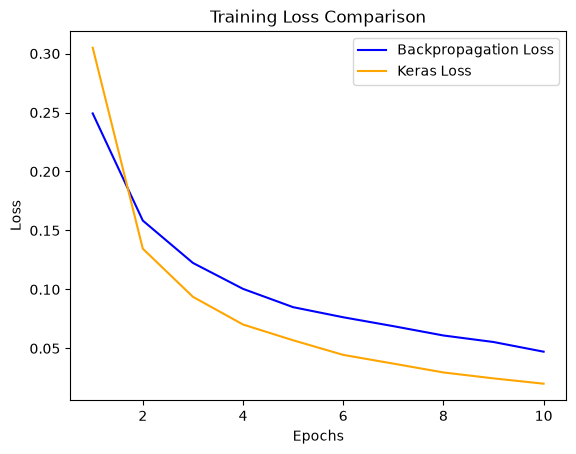

In [9]:
# Plot both loss histories on the same axes.
epoch_range = range(1, epochs + 1)
fig, ax1 = plt.subplots()

ax1.plot(epoch_range, train_losses, label='Backpropagation Loss', color='blue')
ax1.plot(epoch_range, keras_train_losses, label='Keras Loss', color='orange')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Loss')
ax1.set_title('Training Loss Comparison')
ax1.legend()

## 8. Evaluate Both Models on the Test Set

In [10]:
# Compute test loss and accuracy for the manual model.
test_probs = net.forward(x_test)
test_pred = np.argmax(test_probs, axis=1)
test_loss = net.loss(y_test_one_hot, test_probs)
test_accuracy = net.accuracy(y_test_one_hot, test_pred)

# Evaluate the Keras model using the same test examples and labels.
keras_test_loss, keras_test_accuracy = keras_model.evaluate(x_test, y_test_one_hot, verbose=0)
keras_test_pred = np.argmax(keras_model.predict(x_test), axis=1)
keras_test_accuracy = np.mean(np.argmax(y_test_one_hot, axis=1) == keras_test_pred)

results = {
    "Backpropagation": {
        "Test Loss": test_loss,
        "Test Accuracy": test_accuracy
    },
    "Keras": {
        "Test Loss": keras_test_loss,
        "Test Accuracy": keras_test_accuracy
    }
}

print("\nFinal Test Results:")
for method, metrics in results.items():
    print(f"{method} - Loss: {metrics['Test Loss']:.4f}, Accuracy: {metrics['Test Accuracy']:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 313us/step

Final Test Results:
Backpropagation - Loss: 0.0764, Accuracy: 0.9765
Keras - Loss: 0.0708, Accuracy: 0.9775


## 9. Inspect Sample Predictions

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


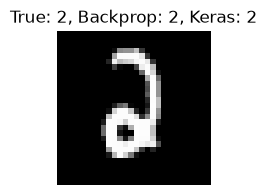

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


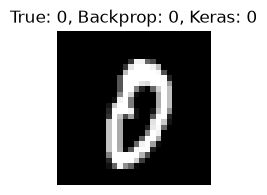

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


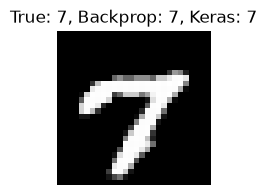

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


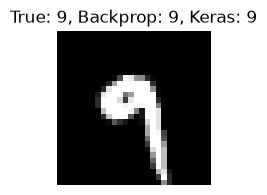

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


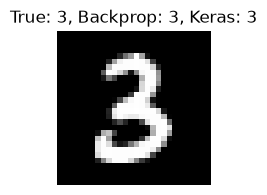

In [11]:
# Display five random test images with predictions from both models.
sample_indices = np.random.choice(x_test.shape[0], size=5, replace=False)
for idx in sample_indices:
    # Restore the image shape for visualization and collect both predictions.
    sample_image = x_test[idx].reshape(28, 28)
    true_label = y_test[idx]
    backprop_pred = net.predict(x_test[idx].reshape(1, -1))[0]
    keras_pred = np.argmax(keras_model.predict(x_test[idx].reshape(1, -1)), axis=1)[0]

    plt.figure(figsize=(2, 2))
    plt.imshow(sample_image, cmap='gray')
    plt.title(f"True: {true_label}, Backprop: {backprop_pred}, Keras: {keras_pred}")
    plt.axis('off')
    plt.show()